In [30]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from zipfile import ZipFile
from sklearn.metrics import roc_auc_score
from scipy.stats import norm

ZIP_PATH = 'jsons.zip'
DELQ_PATH = 'deal_delqs_logs.pq'
MODEL_ID = 'pd-auto-online'
SCORE_COLS = ['final_model_score', 'internal_model_score', 'external_model_score']

In [31]:
def gini(y_true, y_score):
    return 2 * roc_auc_score(y_true, y_score) - 1

In [32]:
def load_model_calls(zip_path, model_id):
    records = []
    with ZipFile(zip_path, 'r') as z:
        for name in z.namelist():
            if not name.endswith('.json'):
                continue
            call = json.loads(z.read(name))
            if call['modelID'] != model_id:
                continue
            records.append({
                'loanID': call['loanID'],
                'eventTime': call['eventTime'],
                **call['values'],
            })
        return pd.DataFrame(records)

calls = load_model_calls(ZIP_PATH, MODEL_ID)
calls['eventTime'] = pd.to_datetime(calls['eventTime'])

print('shape:', calls.shape, '| loanID уникален:', calls['loanID'].is_unique)
calls.head()

shape: (51708, 5) | loanID уникален: True


,loanID,eventTime,final_model_score,internal_model_score,external_model_score
0,CAR20240213645e,2024-02-13 11:27:10.937,0.012619,0.01,0.023097
1,CAR2024010306b1,2024-01-03 16:05:31.680,0.123333,0.08,0.296667
2,CAR202405319f31,2024-05-31 09:50:24.665,0.013257,0.01,0.026287
3,CAR202402034a21,2024-02-03 15:34:44.307,0.035021,0.03,0.055103
4,CAR202401073430,2024-01-07 15:50:25.878,0.024914,0.01,0.084572


In [33]:
print(calls[SCORE_COLS].isna().sum())

n_before = len(calls)
calls = calls.dropna(subset=SCORE_COLS).copy()
print(f'удалено заявок без скора: {n_before - len(calls)} из {n_before}')

final_model_score       2579
internal_model_score    2579
external_model_score       0
dtype: int64
удалено заявок без скора: 2579 из 51708


In [34]:
delq = pd.read_parquet(DELQ_PATH)

delq['period_start_date'] = pd.to_datetime(delq['period_start_date'])
delq['period_end_date'] = pd.to_datetime(delq['period_end_date'])
delq['delq_days'] = (delq['period_end_date'] - delq['period_start_date']).dt.days

delq.head()

,loan_id,period_start_date,period_end_date,delq_days
0,CAR202404241bd6,2024-10-27,2024-11-09,13
1,CAR20240111130f,2024-03-11,2024-05-04,54
2,CAR20240111130f,2024-07-16,2024-09-13,59
3,CAR20240111130f,2024-12-07,2025-02-01,56
4,CAR2024042453fd,2024-07-10,2024-09-06,58


In [35]:
#30@4
calls['score_date'] = calls['eventTime'].dt.normalize()
calls['window_end'] = calls['score_date'] + pd.DateOffset(months=4)

pairs = calls[['loanID', 'score_date', 'window_end']].merge(delq, how='inner', left_on='loanID', right_on='loan_id')

is_default_event = (
    (pairs['period_start_date'] >= pairs['score_date'])
    & (pairs['period_start_date'] <= pairs['window_end'])
    & (pairs['delq_days'] >= 30)
)

default_loans = pairs.loc[is_default_event, 'loanID'].unique()
calls['default_flag'] = calls['loanID'].isin(default_loans).astype(int)

print('заявок:', len(calls))
print('дефолтов:', calls['default_flag'].sum(), f"({calls['default_flag'].mean():.2%})")

заявок: 49129
дефолтов: 3387 (6.89%)


In [36]:
in_window = pairs[
    (pairs['period_start_date'] >= pairs['score_date'])
    & (pairs['period_start_date'] <= pairs['window_end'])
]
print('событий в окне длиной ровно 30 дней:', (in_window['delq_days'] == 30).sum())

событий в окне длиной ровно 30 дней: 4


In [45]:
calls['month'] = calls['eventTime'].dt.to_period('M')

rows = []
for month, part in calls.groupby('month'):
    row = {
        'month': str(month),
        'n_calls': len(part),
        'n_defaults': part['default_flag'].sum(),
    }
    for col in SCORE_COLS:
        short_name = col.replace('_model_score', '')
        row['gini_' + short_name] = gini(part['default_flag'], part[col])
    rows.append(row)

gini_df = pd.DataFrame(rows)
gini_df

,month,n_calls,n_defaults,gini_final,gini_internal,gini_external
0,2024-01,8366,582,0.505326,0.476789,0.268865
1,2024-02,7813,505,0.495358,0.482287,0.217907
2,2024-03,8460,609,0.495311,0.472437,0.242727
3,2024-04,8131,562,0.471593,0.453865,0.210825
4,2024-05,8435,580,0.498285,0.496403,0.193022
5,2024-06,7924,549,0.491538,0.473317,0.197033


In [ ]:
def bootstrap_ci(part, stat_func, n_iter=1000, frac=0.7, conf=0.95, replace=True, seed=42):
    values = np.empty(n_iter)
    for i in range(n_iter):
        sample = part.sample(frac=frac, replace=replace, random_state=seed + i)
        values[i] = stat_func(sample)

    z = norm.ppf(1 - (1 - conf)/2)

    center = np.mean(values) 
    
    spread = z * values.std(ddof=1)
    return center - spread, center + spread

ci_rows = []
for month, part in calls.groupby('month'):
    lo, hi = bootstrap_ci(
        part,
        lambda s: gini(s['default_flag'], s['final_model_score']),
    )
    ci_rows.append({'month': str(month), 'ci_lower': lo, 'ci_upper': hi})

ci_df = pd.DataFrame(ci_rows)
gini_df = gini_df.merge(ci_df, on='month')

# Убедимся, что типы правильные
print(gini_df[['ci_lower', 'ci_upper']].dtypes)  # Должно быть float64

ci_lower    float64
ci_upper    float64
dtype: object


In [47]:
gini_df['uplift'] = gini_df['gini_final'] - gini_df['gini_internal']

uplift_ci = []
for month, part in calls.groupby('month'):
    lo, hi = bootstrap_ci(part, lambda s: gini(s['default_flag'], s['final_model_score']) - gini(s['default_flag'], s['internal_model_score']))
    uplift_ci.append({'month': str(month), 'uplift_lo': lo, 'uplift_hi': hi})

gini_df = gini_df.merge(pd.DataFrame(uplift_ci), on='month')

pp = gini_df.copy()
num_cols = pp.columns.difference(['month', 'n_calls', 'n_default'])
pp[num_cols] = pp[num_cols] * 100
pp.round(2)
        

,month,n_calls,n_defaults,gini_final,gini_internal,gini_external,ci_lower,ci_upper,uplift,uplift_lo,uplift_hi
0,2024-01,8366,58200,50.53,47.68,26.89,45.57,55.47,2.85,1.28,4.41
1,2024-02,7813,50500,49.54,48.23,21.79,43.84,55.12,1.31,-0.31,2.86
2,2024-03,8460,60900,49.53,47.24,24.27,44.70,54.55,2.29,0.60,4.02
3,2024-04,8131,56200,47.16,45.39,21.08,42.12,52.31,1.77,0.18,3.50
4,2024-05,8435,58000,49.83,49.64,19.30,45.11,54.59,0.19,-1.25,1.60
5,2024-06,7924,54900,49.15,47.33,19.70,44.13,54.30,1.82,0.11,3.53


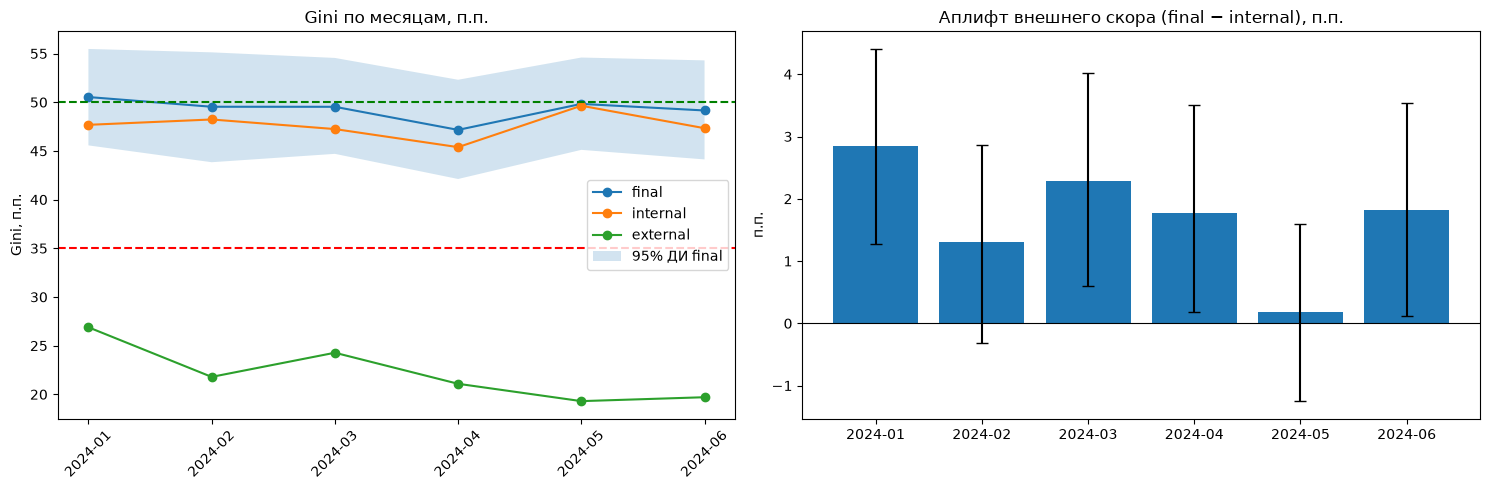

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

ax = axes[0]

x_pos = range(len(pp))

ax.plot(x_pos, pp['gini_final'], marker='o', label='final')
ax.plot(x_pos, pp['gini_internal'], marker='o', label='internal')
ax.plot(x_pos, pp['gini_external'], marker='o', label='external')

ax.fill_between(x_pos, pp['ci_lower'], pp['ci_upper'], alpha=0.2, label='95% ДИ final')


ax.set_xticks(x_pos)
ax.set_xticklabels(pp['month'], rotation=45)
ax.axhline(35, linestyle='--', color='red')
ax.axhline(50, linestyle='--', color='green')
ax.set_title('Gini по месяцам, п.п.')
ax.set_ylabel('Gini, п.п.')
ax.legend()

ax = axes[1]
err_down = pp['uplift'] - pp['uplift_lo']
err_up = pp['uplift_hi'] - pp['uplift']
ax.bar(pp['month'], pp['uplift'], yerr=[err_down, err_up], capsize=4)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Аплифт внешнего скора (final − internal), п.п.')
ax.set_ylabel('п.п.')

plt.tight_layout()
plt.show()

In [49]:
def traffic_light(gini_pp):
    if gini_pp < 35:
        return 'красный'
    elif gini_pp <= 50:
        return 'жёлтый'
    return 'зелёный'


mean_final = pp['gini_final'].mean()
mean_internal = pp['gini_internal'].mean()
mean_external = pp['gini_external'].mean()
mean_uplift = pp['uplift'].mean()

print(f'Средний Gini: final = {mean_final:.2f} п.п., internal = {mean_internal:.2f} п.п., external = {mean_external:.2f} п.п.')
print(f'Средний аплифт: {mean_uplift:+.2f} п.п.')
print(f"Месяцев с положительным аплифтом: {(pp['uplift'] > 0).sum()} из {len(pp)}")
print(f"Месяцев, где аплифт значим (нижняя граница ДИ > 0): {(pp['uplift_lo'] > 0).sum()} из {len(pp)}")
print(f"Светофор для final: {traffic_light(mean_final)} (расстояние до зелёного порога: {50 - mean_final:.2f} п.п.)")
print(f"Верхняя граница ДИ final выше 50 в {(pp['ci_upper'] > 50).sum()} из {len(pp)} месяцев")

Средний Gini: final = 49.29 п.п., internal = 47.58 п.п., external = 22.17 п.п.
Средний аплифт: +1.71 п.п.
Месяцев с положительным аплифтом: 6 из 6
Месяцев, где аплифт значим (нижняя граница ДИ > 0): 4 из 6
Светофор для final: жёлтый (расстояние до зелёного порога: 0.71 п.п.)
Верхняя граница ДИ final выше 50 в 6 из 6 месяцев
